# 🛠️ Feature Engineering: Scaling, Encoding, Selection & Extraction

This notebook provides the **exact syntax** and working implementations for all data preprocessing and feature engineering techniques:

- **1. Feature Scaling**: `StandardScaler`, `MinMaxScaler`, `MaxAbsScaler`, `RobustScaler`
- **2. Label Binarization**: `LabelBinarizer` (with `fit_transform` & `inverse_transform`)
- **3. Categorical Encoding**: `LabelEncoder`, `OrdinalEncoder` (auto & specified categories), `OneHotEncoder`
- **4. Feature Selection**: Filter (`VarianceThreshold`, `SelectKBest`), Wrapper (`RFE`), Embedded (`SelectFromModel`)
- **5. Feature Extraction**: `PCA` & `LDA`
- **6. Summary Cheat Sheet**: When to use each scaler and encoder in exams


## 0. Setup and Data Preparation\nLoad sample datasets and construct representative numerical and categorical features.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

# Visual styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4.5)

# Load dataset
cancer = load_breast_cancer(as_frame=True)
df = cancer.frame

# Numerical Feature Matrix (X) and Target (y)
X = df[['mean radius', 'mean texture', 'mean perimeter', 'mean area']].copy()
y = df['target'].map({0: 'Malignant', 1: 'Benign'})

# Categorical Feature (X_cat) for demonstration: Tumor Size Tier
cat_series = pd.qcut(df['mean radius'], q=3, labels=['Small', 'Medium', 'Large']).astype(str)
X_cat = pd.DataFrame({'size_tier': cat_series})

print("Sample Numerical Features (X):")
print(X.head())

print("\nSample Categorical Feature (X_cat):")
print(X_cat.head())

Sample Numerical Features (X):
   mean radius  mean texture  mean perimeter  mean area
0        17.99         10.38          122.80     1001.0
1        20.57         17.77          132.90     1326.0
2        19.69         21.25          130.00     1203.0
3        11.42         20.38           77.58      386.1
4        20.29         14.34          135.10     1297.0

Sample Categorical Feature (X_cat):
  size_tier
0     Large
1     Large
2     Large
3     Small
4     Large


---
## 1. Feature Scaling

```python
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import MaxAbsScaler, RobustScaler

X_std = StandardScaler().fit_transform(X)
X_min = MinMaxScaler().fit_transform(X)
X_maxabs = MaxAbsScaler().fit_transform(X)
X_robust = RobustScaler().fit_transform(X)
```

- **`StandardScaler`**: Scales to $\mu = 0, \sigma = 1$ (Standard Normal / Z-score).
- **`MinMaxScaler`**: Scales strictly to range $[0, 1]$ (or $[a, b]$).
- **`MaxAbsScaler`**: Scales by dividing by the maximum absolute value (range $[-1, 1]$); preserves zero values for sparse data.
- **`RobustScaler`**: Scales using the median and Interquartile Range ($IQR = Q3 - Q1$), robust to extreme outliers!


=== Comparison of Scalers on 'mean radius' (First 5 Rows) ===
   Raw (Original)  StandardScaler  MinMaxScaler  MaxAbsScaler  RobustScaler
0           17.99          1.0971        0.5210        0.6400        1.1324
1           20.57          1.8298        0.6431        0.7318        1.7647
2           19.69          1.5799        0.6015        0.7005        1.5490
3           11.42         -0.7689        0.2101        0.4063       -0.4779
4           20.29          1.7503        0.6299        0.7218        1.6961


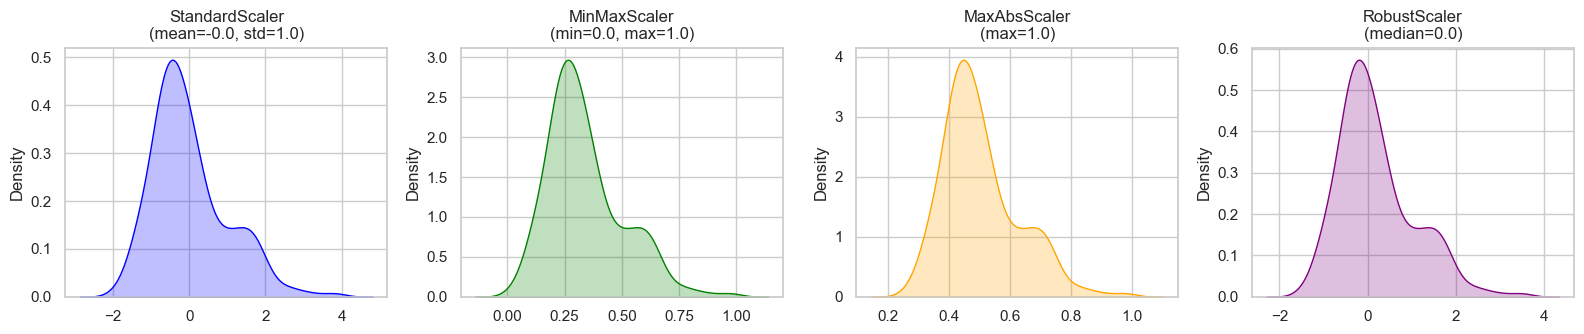

In [2]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import MaxAbsScaler, RobustScaler

# 1. StandardScaler (mean = 0, std = 1)
X_std = StandardScaler().fit_transform(X)

# 2. MinMaxScaler (min = 0, max = 1)
X_min = MinMaxScaler().fit_transform(X)

# 3. MaxAbsScaler (range [-1, 1], preserves zeros)
X_maxabs = MaxAbsScaler().fit_transform(X)

# 4. RobustScaler (uses median & IQR, robust against outliers)
X_robust = RobustScaler().fit_transform(X)

# Display comparison of the first feature ('mean radius') across all scalers
scaler_comparison = pd.DataFrame({
    'Raw (Original)': X.iloc[:, 0],
    'StandardScaler': X_std[:, 0],
    'MinMaxScaler': X_min[:, 0],
    'MaxAbsScaler': X_maxabs[:, 0],
    'RobustScaler': X_robust[:, 0]
})

print("=== Comparison of Scalers on 'mean radius' (First 5 Rows) ===")
print(scaler_comparison.head().round(4))

# Visualizing distributions across the 4 scalers
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))

sns.kdeplot(X_std[:, 0], ax=axes[0], color='blue', fill=True)
axes[0].set_title(f"StandardScaler\n(mean={X_std[:, 0].mean():.1f}, std={X_std[:, 0].std():.1f})")

sns.kdeplot(X_min[:, 0], ax=axes[1], color='green', fill=True)
axes[1].set_title(f"MinMaxScaler\n(min={X_min[:, 0].min():.1f}, max={X_min[:, 0].max():.1f})")

sns.kdeplot(X_maxabs[:, 0], ax=axes[2], color='orange', fill=True)
axes[2].set_title(f"MaxAbsScaler\n(max={X_maxabs[:, 0].max():.1f})")

sns.kdeplot(X_robust[:, 0], ax=axes[3], color='purple', fill=True)
axes[3].set_title(f"RobustScaler\n(median={np.median(X_robust[:, 0]):.1f})")

plt.tight_layout()
plt.show()

---
## 2. Label Binarizer

Binarizes target labels in a one-vs-all fashion:

```python
from sklearn.preprocessing import LabelBinarizer

lb = LabelBinarizer(
    neg_label=0, pos_label=1, sparse_output=False
)
y_bin = lb.fit_transform(y)
y_inv = lb.inverse_transform(y_bin)
```


In [3]:
from sklearn.preprocessing import LabelBinarizer

# Initialize LabelBinarizer with explicit negative and positive label encodings
lb = LabelBinarizer(
    neg_label=0, pos_label=1, sparse_output=False
)

# Transform text labels ('Malignant', 'Benign') into 0 and 1
y_bin = lb.fit_transform(y)

# Inverse transform back to original string classes
y_inv = lb.inverse_transform(y_bin)

# Verification table
bin_demo_df = pd.DataFrame({
    'Original Label (y)': y[:6],
    'Binarized (y_bin)': y_bin[:6].ravel(),
    'Inversed (y_inv)': y_inv[:6]
})

print("=== Label Binarizer Demo ===")
print("Classes learned:", lb.classes_)
print(bin_demo_df)

=== Label Binarizer Demo ===
Classes learned: ['Benign' 'Malignant']
  Original Label (y)  Binarized (y_bin) Inversed (y_inv)
0          Malignant                  1        Malignant
1          Malignant                  1        Malignant
2          Malignant                  1        Malignant
3          Malignant                  1        Malignant
4          Malignant                  1        Malignant
5          Malignant                  1        Malignant


---
## 3. Categorical Encoding

```python
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, LabelEncoder

# 1. LabelEncoder: for 1D target arrays or series
X_le = LabelEncoder().fit_transform(X_cat)

# 2. OrdinalEncoder: automatic alphabetical categories
X_ord = OrdinalEncoder().fit_transform(X_cat)

# 3. OrdinalEncoder with specified categories order:
X_ord = OrdinalEncoder(categories=<categories_list>).fit_transform(X_cat)

# 4. OneHotEncoder: binary dummy indicator columns
X_oh = OneHotEncoder(
    handle_unknown=<"ignore"/"error">
).fit_transform(X_cat).toarray()
```


In [4]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, LabelEncoder

# 1. LabelEncoder (1D Array)
le = LabelEncoder()
X_le = le.fit_transform(X_cat['size_tier'])

# 2. OrdinalEncoder (Auto categories - Alphabetical order)
ord_auto = OrdinalEncoder()
X_ord_auto = ord_auto.fit_transform(X_cat[['size_tier']])

# 3. OrdinalEncoder with specified custom sequence: Small (0) < Medium (1) < Large (2)
categories_list = [['Small', 'Medium', 'Large']]
ord_custom = OrdinalEncoder(categories=categories_list)
X_ord = ord_custom.fit_transform(X_cat[['size_tier']])

# 4. OneHotEncoder (handle_unknown="ignore" handles unseen exam categories without crashing)
ohe = OneHotEncoder(handle_unknown="ignore")
X_oh = ohe.fit_transform(X_cat[['size_tier']]).toarray()

# Build comparison DataFrame
encoding_summary = pd.DataFrame({
    'Category': X_cat['size_tier'],
    'LabelEncoder (X_le)': X_le,
    'Ordinal (Auto)': X_ord_auto.ravel(),
    'Ordinal (Custom: S<M<L)': X_ord.ravel()
}).drop_duplicates().sort_values('Ordinal (Custom: S<M<L)')

print("=== Label & Ordinal Encoding Comparison ===")
print(encoding_summary.to_string(index=False))

print("\n=== One-Hot Encoded Array (X_oh) ===")
ohe_feature_names = ohe.get_feature_names_out(['size_tier'])
ohe_df = pd.DataFrame(X_oh, columns=ohe_feature_names)
print(pd.concat([X_cat[['size_tier']], ohe_df], axis=1).drop_duplicates().to_string(index=False))

=== Label & Ordinal Encoding Comparison ===
Category  LabelEncoder (X_le)  Ordinal (Auto)  Ordinal (Custom: S<M<L)
   Small                    2             2.0                      0.0
  Medium                    1             1.0                      1.0
   Large                    0             0.0                      2.0

=== One-Hot Encoded Array (X_oh) ===
size_tier  size_tier_Large  size_tier_Medium  size_tier_Small
    Large              1.0               0.0              0.0
    Small              0.0               0.0              1.0
   Medium              0.0               1.0              0.0


---
## 4. Feature Selection

Simple syntax for **Filter**, **Wrapper**, and **Embedded** feature selection:

```python
# Filter Methods:
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
selector_var = VarianceThreshold(threshold=0.01).fit(X)
selector_kbest = SelectKBest(score_func=f_classif, k=2).fit(X_std, y_bin.ravel())

# Wrapper Method:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
rfe = RFE(estimator=LogisticRegression(), n_features_to_select=2).fit(X_std, y_bin.ravel())

# Embedded Method:
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier
sfm = SelectFromModel(RandomForestClassifier(n_estimators=50, random_state=42), threshold="median").fit(X_std, y_bin.ravel())
```


In [5]:
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif, RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

y_target = y_bin.ravel()

# 1. VarianceThreshold (Removes low-variance features)
sel_var = VarianceThreshold(threshold=0.01).fit(X)
print("1. VarianceThreshold retained:", list(X.columns[sel_var.get_support()]))

# 2. SelectKBest (ANOVA F-test, selects top 2 features)
sel_kbest = SelectKBest(score_func=f_classif, k=2).fit(X_std, y_target)
print("2. SelectKBest (k=2) retained: ", list(X.columns[sel_kbest.get_support()]))

# 3. RFE (Recursive Feature Elimination with Logistic Regression)
rfe = RFE(estimator=LogisticRegression(), n_features_to_select=2).fit(X_std, y_target)
print("3. RFE (k=2) retained:         ", list(X.columns[rfe.support_]))

# 4. SelectFromModel (Embedded tree-based selection)
sfm = SelectFromModel(RandomForestClassifier(n_estimators=50, random_state=42), threshold="median")
sfm.fit(X_std, y_target)
print("4. SelectFromModel retained:   ", list(X.columns[sfm.get_support()]))

1. VarianceThreshold retained: ['mean radius', 'mean texture', 'mean perimeter', 'mean area']
2. SelectKBest (k=2) retained:  ['mean radius', 'mean perimeter']
3. RFE (k=2) retained:          ['mean texture', 'mean perimeter']


4. SelectFromModel retained:    ['mean perimeter', 'mean area']


---
## 5. Feature Extraction (Dimensionality Reduction)

```python
# Unsupervised: Principal Component Analysis (PCA)
from sklearn.decomposition import PCA
X_pca = PCA(n_components=2).fit_transform(X_std)

# Supervised: Linear Discriminant Analysis (LDA)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
X_lda = LDA(n_components=1).fit_transform(X_std, y_target)
```


PCA Total Variance Explained (2 components): 99.53%
LDA Transformed Shape: (569, 1)


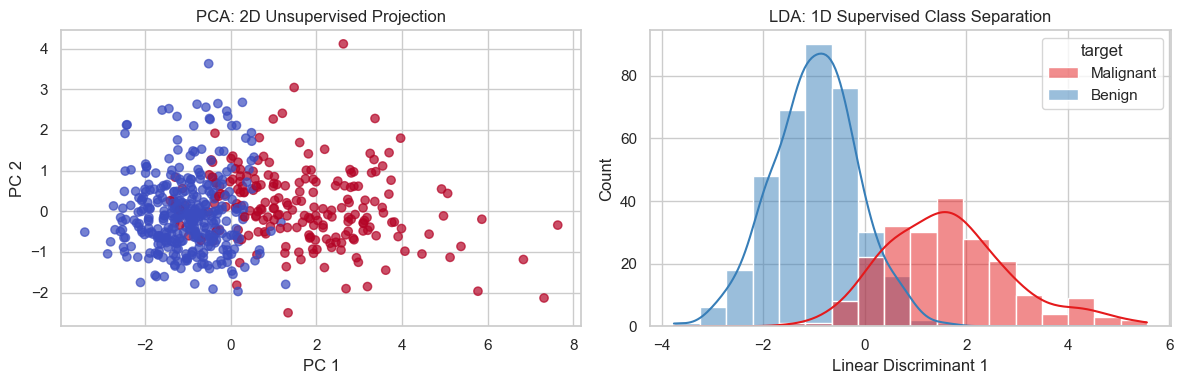

In [6]:
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

# 1. PCA (Projects 4 features into 2 orthogonal components)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_std)
print(f"PCA Total Variance Explained (2 components): {pca.explained_variance_ratio_.sum()*100:.2f}%")

# 2. LDA (Projects 4 features into 1 discriminant axis maximizing class separation)
lda = LDA(n_components=1)
X_lda = lda.fit_transform(X_std, y_target)
print(f"LDA Transformed Shape: {X_lda.shape}")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y_target, cmap='coolwarm', alpha=0.7)
axes[0].set_title("PCA: 2D Unsupervised Projection")
axes[0].set_xlabel("PC 1")
axes[0].set_ylabel("PC 2")

sns.histplot(x=X_lda.ravel(), hue=y, kde=True, ax=axes[1], palette='Set1')
axes[1].set_title("LDA: 1D Supervised Class Separation")
axes[1].set_xlabel("Linear Discriminant 1")

plt.tight_layout()
plt.show()

---
## 6. 🎓 Exam Quick Reference: Which Scaler & Encoder to Choose?

### Feature Scalers:
| Scaler | Output Range | Key Formula | Best Used For |
|---|:---:|---|---|
| **`StandardScaler()`** | $\mu=0, \sigma=1$ | $z = \frac{x - \mu}{\sigma}$ | Standard default for **Logistic Regression, SVM, KNN, PCA** |
| **`MinMaxScaler()`** | $[0, 1]$ | $x' = \frac{x - x_{min}}{x_{max} - x_{min}}$ | Bounded data, Neural Networks, **MultinomialNB** |
| **`RobustScaler()`** | Centered at $0$ | $x' = \frac{x - \text{median}}{IQR}$ | **Datasets with strong outliers** (uses median & IQR) |
| **`MaxAbsScaler()`** | $[-1, 1]$ | $x' = \frac{x}{\max(|x|)}$ | **Sparse datasets** / matrices with many zeros |

---

### Categorical Encoders:
| Encoder | Input | Output | When to Use |
|---|:---:|:---:|---|
| **`LabelBinarizer()`** | 1D target $y$ | Binary vector ($0$ or $1$) | Binary target classification formatting |
| **`LabelEncoder()`** | 1D array/series | Integers ($0, 1, 2, \dots$) | Strictly for **target labels ($y$)**, not feature matrix $X$ |
| **`OrdinalEncoder(categories=...)`** | 2D matrix ($X$) | Sequential integers ($0, 1, 2, \dots$) | Ordered features where rank matters (**Small < Medium < Large**) |
| **`OneHotEncoder(handle_unknown='ignore')`** | 2D matrix ($X$) | Binary dummy columns ($0$ and $1$) | Nominal features with no natural order (**Red, Blue, Green**) |
